Buscando en: C:\Users\provo\OneDrive\Escritorio\Proyecto AcP\data\gtzan
¿Existe la ruta?: True
----------------------------------------
Total de pistas WAV encontradas: 1000


,category,n_wav,percentage
0,blues,100,10.0
1,classical,100,10.0
2,country,100,10.0
3,disco,100,10.0
4,hiphop,100,10.0
5,jazz,100,10.0
6,metal,100,10.0
7,pop,100,10.0
8,reggae,100,10.0
9,rock,100,10.0


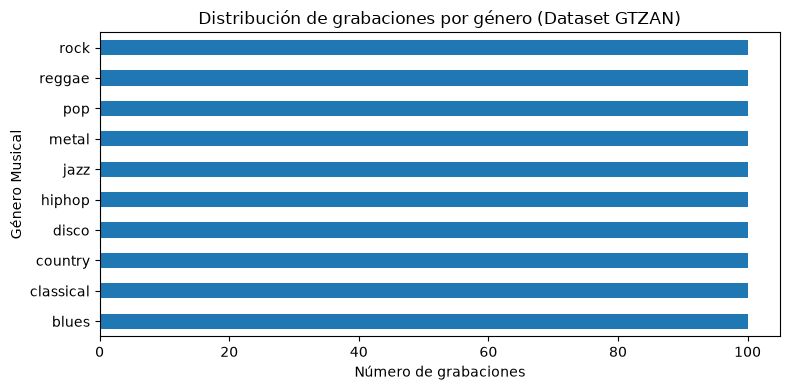

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

# 1. Localizar la carpeta del dataset (usamos ../ porque el notebook está dentro de 'notebooks')
DATA_ROOT = Path("../data/gtzan")

print(f"Buscando en: {DATA_ROOT.resolve()}")
print(f"¿Existe la ruta?: {DATA_ROOT.exists()}")

# 2. Buscar recursivamente todos los archivos .wav
wav_paths = sorted(DATA_ROOT.rglob("*.wav"))

# 3. Construir el DataFrame con las categorías (géneros) extraídas del nombre de la carpeta
corpus = pd.DataFrame({
    "category": [p.parent.name for p in wav_paths],
    "path": [p.relative_to(DATA_ROOT).as_posix() for p in wav_paths],
})

# 4. Contar la cantidad de audios por género y sacar el porcentaje
counts = (
    corpus["category"]
    .value_counts()
    .rename_axis("category")
    .reset_index(name="n_wav")
)
counts["percentage"] = (100 * counts["n_wav"] / counts["n_wav"].sum()).round(1)

print("-" * 40)
print(f"Total de pistas WAV encontradas: {len(corpus)}")
display(counts)

# 5. Visualizar la distribución tal como lo pide el profesor
ax = counts.sort_values("n_wav").plot(
    x="category", y="n_wav", kind="barh",
    legend=False, figsize=(8, 4), color="#1f77b4"
)
ax.set_xlabel("Número de grabaciones")
ax.set_ylabel("Género Musical")
ax.set_title("Distribución de grabaciones por género (Dataset GTZAN)")
plt.tight_layout()
plt.show()